# 3. The Black-Scholes PDE and finite differences

The option value $V(S,t)$ satisfies

$$\frac{\partial V}{\partial t} + \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + (r-q)S\frac{\partial V}{\partial S} - rV = 0 .$$

With $x = \ln S$, $\tau = T - t$ and a rescaling of $V$, this becomes the **heat equation** $\partial u/\partial\tau = \tfrac{1}{2}\sigma^2\,\partial^2 u/\partial x^2$: the option value diffuses backwards from the payoff, exactly like a temperature profile. The numerical methods of heat conduction therefore apply directly.

In [1]:
import sys
sys.path.insert(0, "..")  # make the `pricer` package importable from the notebooks folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pricer import VanillaOption, black_scholes, monte_carlo, binomial, finite_difference, exotics
from pricer.greeks import bump_greeks
from pricer.plotting import use_style, BLUE, ORANGE, AQUA, YELLOW, MUTED, INK_SOFT

use_style()
pd.options.display.float_format = "{:.4f}".format

# Reference contract used throughout: an at-the-money one-year option.
call = VanillaOption(spot=100, strike=100, maturity=1.0, rate=0.05, vol=0.2, option_type="call")
put = call.with_(option_type="put")

## 3.1 Diffusion of the payoff

Solving the PDE gives the value on the whole price grid at once. Starting from the kinked payoff at expiry, the solution is smoothed out as the time to maturity grows.

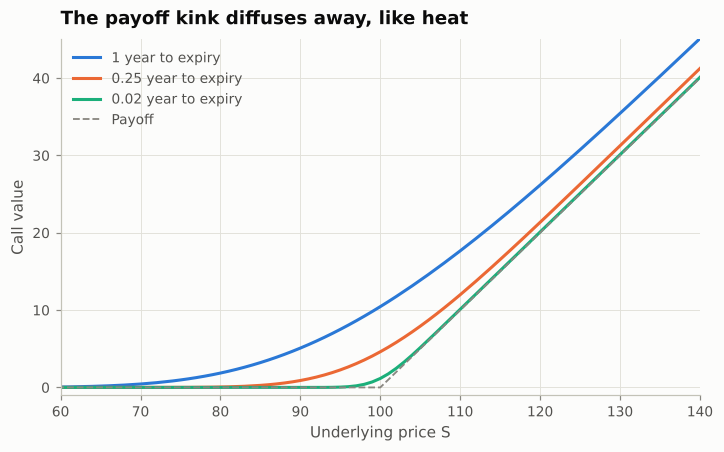

In [2]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for maturity, color in [(1.0, BLUE), (0.25, ORANGE), (0.02, AQUA)]:
    solution = finite_difference.solve(call.with_(maturity=maturity))
    ax.plot(solution.grid, solution.values, color=color, label=f"{maturity:g} year to expiry")
ax.plot(solution.grid, call.payoff(solution.grid), color=MUTED, linestyle="--", linewidth=1.2, label="Payoff")
ax.set_xlim(60, 140); ax.set_ylim(-1, 45)
ax.set_xlabel("Underlying price S"); ax.set_ylabel("Call value")
ax.set_title("The payoff kink diffuses away, like heat"); ax.legend();

## 3.2 Three time-stepping schemes

All three are the $\theta$-scheme $\;(I - \theta\,\Delta\tau\,L)\,V^{n+1} = (I + (1-\theta)\,\Delta\tau\,L)\,V^{n}$, where $L$ is the discretised spatial operator:

| Scheme | $\theta$ | Cost per step | Stability | Order in time |
|---|---|---|---|---|
| Explicit | 0 | one matrix product | conditional | 1 |
| Implicit | 1 | one tridiagonal solve | unconditional | 1 |
| Crank-Nicolson | 1/2 | one tridiagonal solve | unconditional | 2 |

In [3]:
exact = black_scholes.price(call)
rows = []
for scheme in ["explicit", "implicit", "crank-nicolson"]:
    for n_time in [200, 4000]:
        result = finite_difference.solve(call, n_space=200, n_time=n_time, scheme=scheme)
        rows.append({"Scheme": scheme, "Time steps": n_time,
                     "Price": result.price if result.is_stable else np.nan,
                     "Error": result.price - exact if result.is_stable else np.nan,
                     "Stable": result.is_stable})
pd.DataFrame(rows).set_index(["Scheme", "Time steps"])

Price   Error  Stable
Scheme         Time steps                        
explicit       200            NaN     NaN   False
               4000       10.4409 -0.0096    True
implicit       200        10.4354 -0.0152    True
               4000       10.4404 -0.0102    True
crank-nicolson 200        10.4407 -0.0099    True
               4000       10.4407 -0.0099    True

### The instability of the explicit scheme

The explicit scheme is stable only if $\Delta\tau \lesssim \Delta S^2 / (\sigma^2 S_{\max}^2)$, the same condition as $\Delta t \le \Delta x^2/(2D)$ for the heat equation. Halving the price step therefore requires four times more time steps. Above the limit, errors are amplified at every step and oscillations grow from the high-price end of the grid.

Sufficient condition: dt <= 0.00250, i.e. at least 402 time steps for 100 price steps


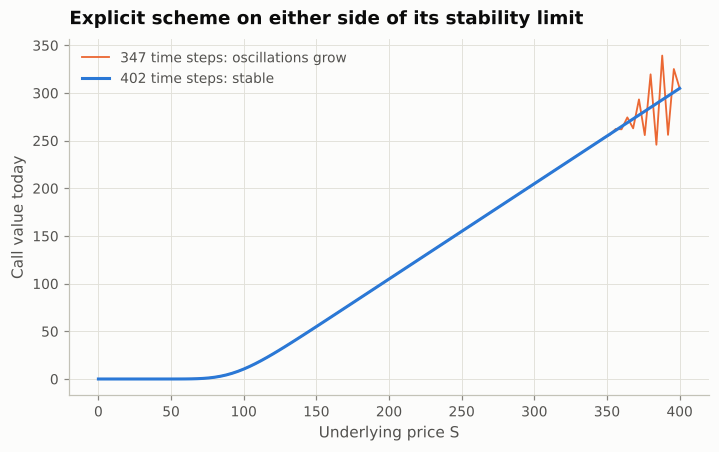

In [4]:
n_space, s_max = 100, 400.0
limit = finite_difference.explicit_stability_limit(call, n_space, s_max)
n_stable = int(np.ceil(call.maturity / limit)) + 1
stable = finite_difference.solve(call, n_space, n_stable, "explicit")
print(f"Sufficient condition: dt <= {limit:.5f}, i.e. at least {n_stable} time steps for {n_space} price steps")

# Reduce the number of time steps until the oscillations are visible.
n_unstable, unstable = n_stable, stable
while np.abs(unstable.values - stable.values).max() < 25:
    n_unstable -= 1
    unstable = finite_difference.solve(call, n_space, n_unstable, "explicit")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(unstable.grid, unstable.values, color=ORANGE, linewidth=1.2, label=f"{n_unstable} time steps: oscillations grow")
ax.plot(stable.grid, stable.values, color=BLUE, label=f"{n_stable} time steps: stable")
ax.set_xlabel("Underlying price S"); ax.set_ylabel("Call value today")
ax.set_title("Explicit scheme on either side of its stability limit"); ax.legend();

In [5]:
rows = []
for n_time in [n_unstable, n_unstable - 20, n_unstable - 60]:
    result = finite_difference.solve(call, n_space, n_time, "explicit")
    rows.append({"Time steps": n_time, "Largest |value| on the grid": np.abs(result.values).max()})
pd.DataFrame(rows).set_index("Time steps").style.format("{:.3e}")

,Largest |value| on the grid
Time steps,
347,3.393e+02
327,1.178e+17
287,3.554e+42


### Order of convergence in time

On a very fine price grid the remaining error comes from the time discretisation. Doubling the number of time steps halves the error of the implicit scheme and divides the Crank-Nicolson error by four.

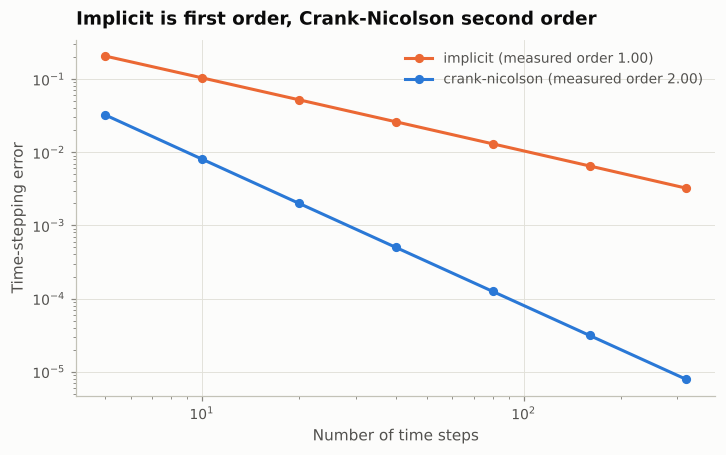

In [6]:
time_steps = np.array([5, 10, 20, 40, 80, 160, 320])
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for scheme, color in [("implicit", ORANGE), ("crank-nicolson", BLUE)]:
    reference = finite_difference.price(call, n_space=3200, n_time=20_000, scheme=scheme)
    errors = [abs(finite_difference.price(call, n_space=3200, n_time=int(n), scheme=scheme) - reference)
              for n in time_steps]
    order = -np.polyfit(np.log(time_steps), np.log(errors), 1)[0]
    ax.loglog(time_steps, errors, marker="o", color=color, label=f"{scheme} (measured order {order:.2f})")
ax.set_xlabel("Number of time steps"); ax.set_ylabel("Time-stepping error")
ax.set_title("Implicit is first order, Crank-Nicolson second order"); ax.legend();

### Why the first Crank-Nicolson steps are implicit

Crank-Nicolson barely damps high-frequency modes, and the kink of the payoff at the strike excites them. The price is still accurate, but its second derivative (gamma) oscillates near the strike. Replacing the first two steps by implicit half-steps (Rannacher start-up) removes the problem while keeping second-order accuracy.

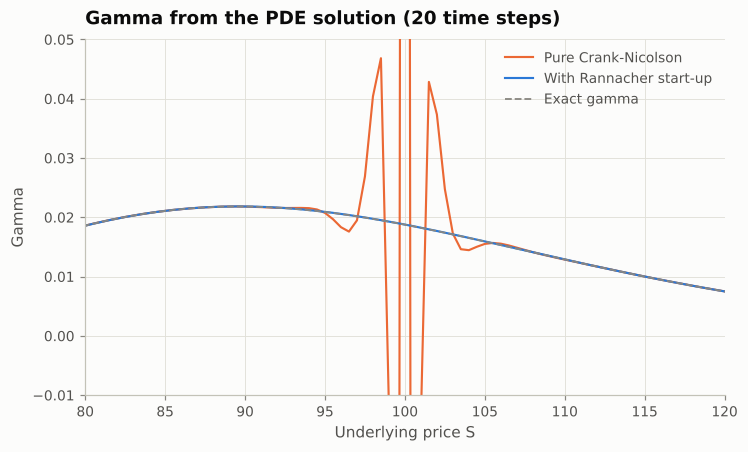

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for steps, color, label in [(0, ORANGE, "Pure Crank-Nicolson"), (2, BLUE, "With Rannacher start-up")]:
    solution = finite_difference.solve(call, n_space=800, n_time=20, rannacher_steps=steps)
    ds = solution.grid[1] - solution.grid[0]
    gamma = np.diff(solution.values, 2) / ds**2
    ax.plot(solution.grid[1:-1], gamma, color=color, linewidth=1.4, label=label)
exact_gamma = [black_scholes.gamma(call.with_(spot=s)) for s in solution.grid[1:-1]]
ax.plot(solution.grid[1:-1], exact_gamma, color=MUTED, linestyle="--", linewidth=1.2, label="Exact gamma")
ax.set_xlim(80, 120); ax.set_ylim(-0.01, 0.05)
ax.set_xlabel("Underlying price S"); ax.set_ylabel("Gamma")
ax.set_title("Gamma from the PDE solution (20 time steps)"); ax.legend();

## 3.3 American options

Early exercise turns the PDE into a free-boundary problem. The simplest treatment is to enforce $V \ge \text{payoff}$ after every time step. The result agrees with the binomial tree.

In [8]:
rows = []
for strike in [90, 100, 110]:
    option = put.with_(strike=strike)
    rows.append({"Strike": strike,
                 "Finite differences": finite_difference.price(option, n_space=800, n_time=800, american=True),
                 "Binomial tree": binomial.price(option, 2000, american=True),
                 "European (exact)": black_scholes.price(option)})
pd.DataFrame(rows).set_index("Strike")

,Finite differences,Binomial tree,European (exact)
Strike,,,
90,2.4713,2.4726,2.3101
100,6.0889,6.0900,5.5735
110,11.9715,11.9732,10.6753


## Summary

* The Black-Scholes PDE is a heat equation in disguise; the same schemes and the same stability condition apply.
* The explicit scheme is only conditionally stable; implicit and Crank-Nicolson are unconditionally stable.
* Crank-Nicolson is second order in time, and a short implicit start-up keeps its Greeks smooth.